# Feature Valiadation

In [39]:
# ===========================================
# Import Required Libraries
# ===========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Plot style
plt.style.use('ggplot')

print("Libraries imported successfully.")

Libraries imported successfully.


In [40]:
from google.colab import drive
drive.mount("/content/drive")



# ===========================================
# Load Dataset
# ===========================================



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:
file_path = "/content/drive/MyDrive/My Thesis/air_quality_feature_engineered.csv"

air_model = pd.read_csv(file_path)

print("Dataset loaded successfully.")

print("="*70)

air_model.head()

Dataset loaded successfully.


,date,PM10,PM2.5,RH,Temp,WD,WS,Hour,DayOfWeek,Weekend,Day,Month,Quarter,Year,DayOfYear,Season,Harmattan,Hour_sin,Hour_cos,WD_sin,WD_cos,Month_sin,Month_cos,PM2.5_lag1,PM2.5_lag3,PM2.5_lag6,PM2.5_lag12,PM2.5_lag24,PM2.5_rollmean6,PM2.5_rollmean12,PM2.5_rollmean24,PM2.5_rollstd24,Temp_RH,PM2.5_RH,PM2.5_PM10_ratio
0,2024-01-01 00:00:00,223.814714,65.119368,94.011898,28.618305,260.566102,0.604881,0,0,0,1,1,1,2024,1,Dry_Season,1,0.000000,1.000000,-0.986475,-0.163910,0.5,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2690.461181,6121.995424,0.290952
1,2024-01-01 01:00:00,343.645577,108.224682,91.278436,28.438167,279.908333,1.534783,1,0,0,1,1,1,2024,1,Dry_Season,1,0.258819,0.965926,-0.985084,0.172072,0.5,0.866025,65.119368,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2595.791370,9878.579726,0.314931
2,2024-01-01 02:00:00,445.856723,140.734862,91.814506,27.912167,285.158333,1.327000,2,0,0,1,1,1,2024,1,Dry_Season,1,0.500000,0.866025,-0.965207,0.261487,0.5,0.866025,108.224682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2562.741790,12921.501769,0.315650
3,2024-01-01 03:00:00,407.405071,138.152391,90.311495,27.583500,289.420000,1.447833,3,0,0,1,1,1,2024,1,Dry_Season,1,0.707107,0.707107,-0.943107,0.332490,0.5,0.866025,140.734862,65.119368,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2491.107120,12476.748949,0.339103
4,2024-01-01 04:00:00,400.491289,126.808911,89.519261,27.357000,286.768333,1.326083,4,0,0,1,1,1,2024,1,Dry_Season,1,0.866025,0.500000,-0.957479,0.288503,0.5,0.866025,138.152391,108.224682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2448.978415,11351.839990,0.316633


In [42]:
print(f"Rows    : {air_model.shape[0]}")
print(f"Columns : {air_model.shape[1]}")

Rows    : 17544
Columns : 35


In [43]:
air_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 35 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              17544 non-null  object 
 1   PM10              17544 non-null  float64
 2   PM2.5             17544 non-null  float64
 3   RH                17544 non-null  float64
 4   Temp              17544 non-null  float64
 5   WD                17544 non-null  float64
 6   WS                15263 non-null  float64
 7   Hour              17544 non-null  int64  
 8   DayOfWeek         17544 non-null  int64  
 9   Weekend           17544 non-null  int64  
 10  Day               17544 non-null  int64  
 11  Month             17544 non-null  int64  
 12  Quarter           17544 non-null  int64  
 13  Year              17544 non-null  int64  
 14  DayOfYear         17544 non-null  int64  
 15  Season            17544 non-null  object 
 16  Harmattan         17544 non-null  int64 

In [44]:
missing = (
    air_model.isna()
             .sum()
             .sort_values(ascending=False)
)

missing[missing > 0]

,0
WS,2281
PM2.5_lag24,24
PM2.5_rollmean24,23
PM2.5_rollstd24,23
PM2.5_lag12,12
PM2.5_rollmean12,11
PM2.5_lag6,6
PM2.5_rollmean6,5
PM2.5_lag3,3
PM2.5_lag1,1


In [45]:
air_model.duplicated().sum()

np.int64(0)

In [46]:
import numpy as np

np.isinf(
    air_model.select_dtypes(include=np.number)
).sum().sum()

np.int64(0)

In [47]:
air_model.describe().T

,count,mean,std,min,25%,50%,75%,max
PM10,17544.0,7.602739e+01,119.969174,4.638015,29.786499,4.235632e+01,75.733033,1496.487150
PM2.5,17544.0,2.472443e+01,27.088971,1.540185,12.329761,1.727453e+01,26.921815,249.604800
RH,17544.0,9.113083e+01,10.319742,25.850500,87.586667,9.604637e+01,97.653097,99.900000
Temp,17544.0,2.817899e+01,2.785510,22.265167,26.069458,2.782850e+01,29.906375,36.717241
WD,17544.0,2.225547e+02,57.144239,5.736000,191.830833,2.267283e+02,266.308750,354.800000
WS,15263.0,9.160215e-01,1.136848,0.001000,0.248942,3.934833e-01,1.478175,19.850000
Hour,17544.0,1.150000e+01,6.922384,0.000000,5.750000,1.150000e+01,17.250000,23.000000
DayOfWeek,17544.0,2.991792e+00,2.000724,0.000000,1.000000,3.000000e+00,5.000000,6.000000
Weekend,17544.0,2.845417e-01,0.451209,0.000000,0.000000,0.000000e+00,1.000000,1.000000
Day,17544.0,1.573871e+01,8.804172,1.000000,8.000000,1.600000e+01,23.000000,31.000000


In [48]:
air_model.isnull().any(axis=1).sum()

np.int64(2305)

In [49]:
air_model["WS"].isna().sum()

np.int64(2281)

In [50]:
# Create modelling dataset without Wind Speed
air_model_final = (
    air_model
    .drop(columns=["WS"])
    .dropna()
    .copy()
)

In [51]:
# Verify the dataset
print("Feature-engineered dataset :", air_model.shape)
print("Final modelling dataset    :", air_model_final.shape)

print("\nRemaining missing values:")
print(air_model_final.isna().sum().sum())

Feature-engineered dataset : (17544, 35)
Final modelling dataset    : (17520, 34)

Remaining missing values:
0


In [52]:
# Save the Final dataset for Modelling
air_model_final.to_csv(
    "air_quality_model.csv",
    index=True
)

print("✅ Final modelling dataset saved successfully.")

✅ Final modelling dataset saved successfully.


# Feacture Selection

In [53]:
# Correlation with PM2.5
corr_target = (
    air_model_final
    .select_dtypes(include=np.number)
    .corr()["PM2.5"]
    .sort_values(ascending=False)
)

corr_target




,PM2.5
PM2.5,1.000000
PM2.5_lag1,0.985608
PM2.5_rollmean6,0.978991
PM10,0.973344
PM2.5_rollmean12,0.961216
PM2.5_lag3,0.955510
PM2.5_RH,0.945344
PM2.5_rollmean24,0.944103
PM2.5_lag6,0.927399
PM2.5_lag12,0.890256


In [54]:
corr_target.to_frame(name="Correlation")

,Correlation
PM2.5,1.000000
PM2.5_lag1,0.985608
PM2.5_rollmean6,0.978991
PM10,0.973344
PM2.5_rollmean12,0.961216
PM2.5_lag3,0.955510
PM2.5_RH,0.945344
PM2.5_rollmean24,0.944103
PM2.5_lag6,0.927399
PM2.5_lag12,0.890256


In [55]:
#Absolute correlation ranking
corr_abs = (
    corr_target.abs()
               .sort_values(ascending=False)
)

corr_abs

,PM2.5
PM2.5,1.000000
PM2.5_lag1,0.985608
PM2.5_rollmean6,0.978991
PM10,0.973344
PM2.5_rollmean12,0.961216
PM2.5_lag3,0.955510
PM2.5_RH,0.945344
PM2.5_rollmean24,0.944103
PM2.5_lag6,0.927399
PM2.5_lag12,0.890256


In [56]:
corr_abs.to_csv("feature_correlation_ranking.csv")

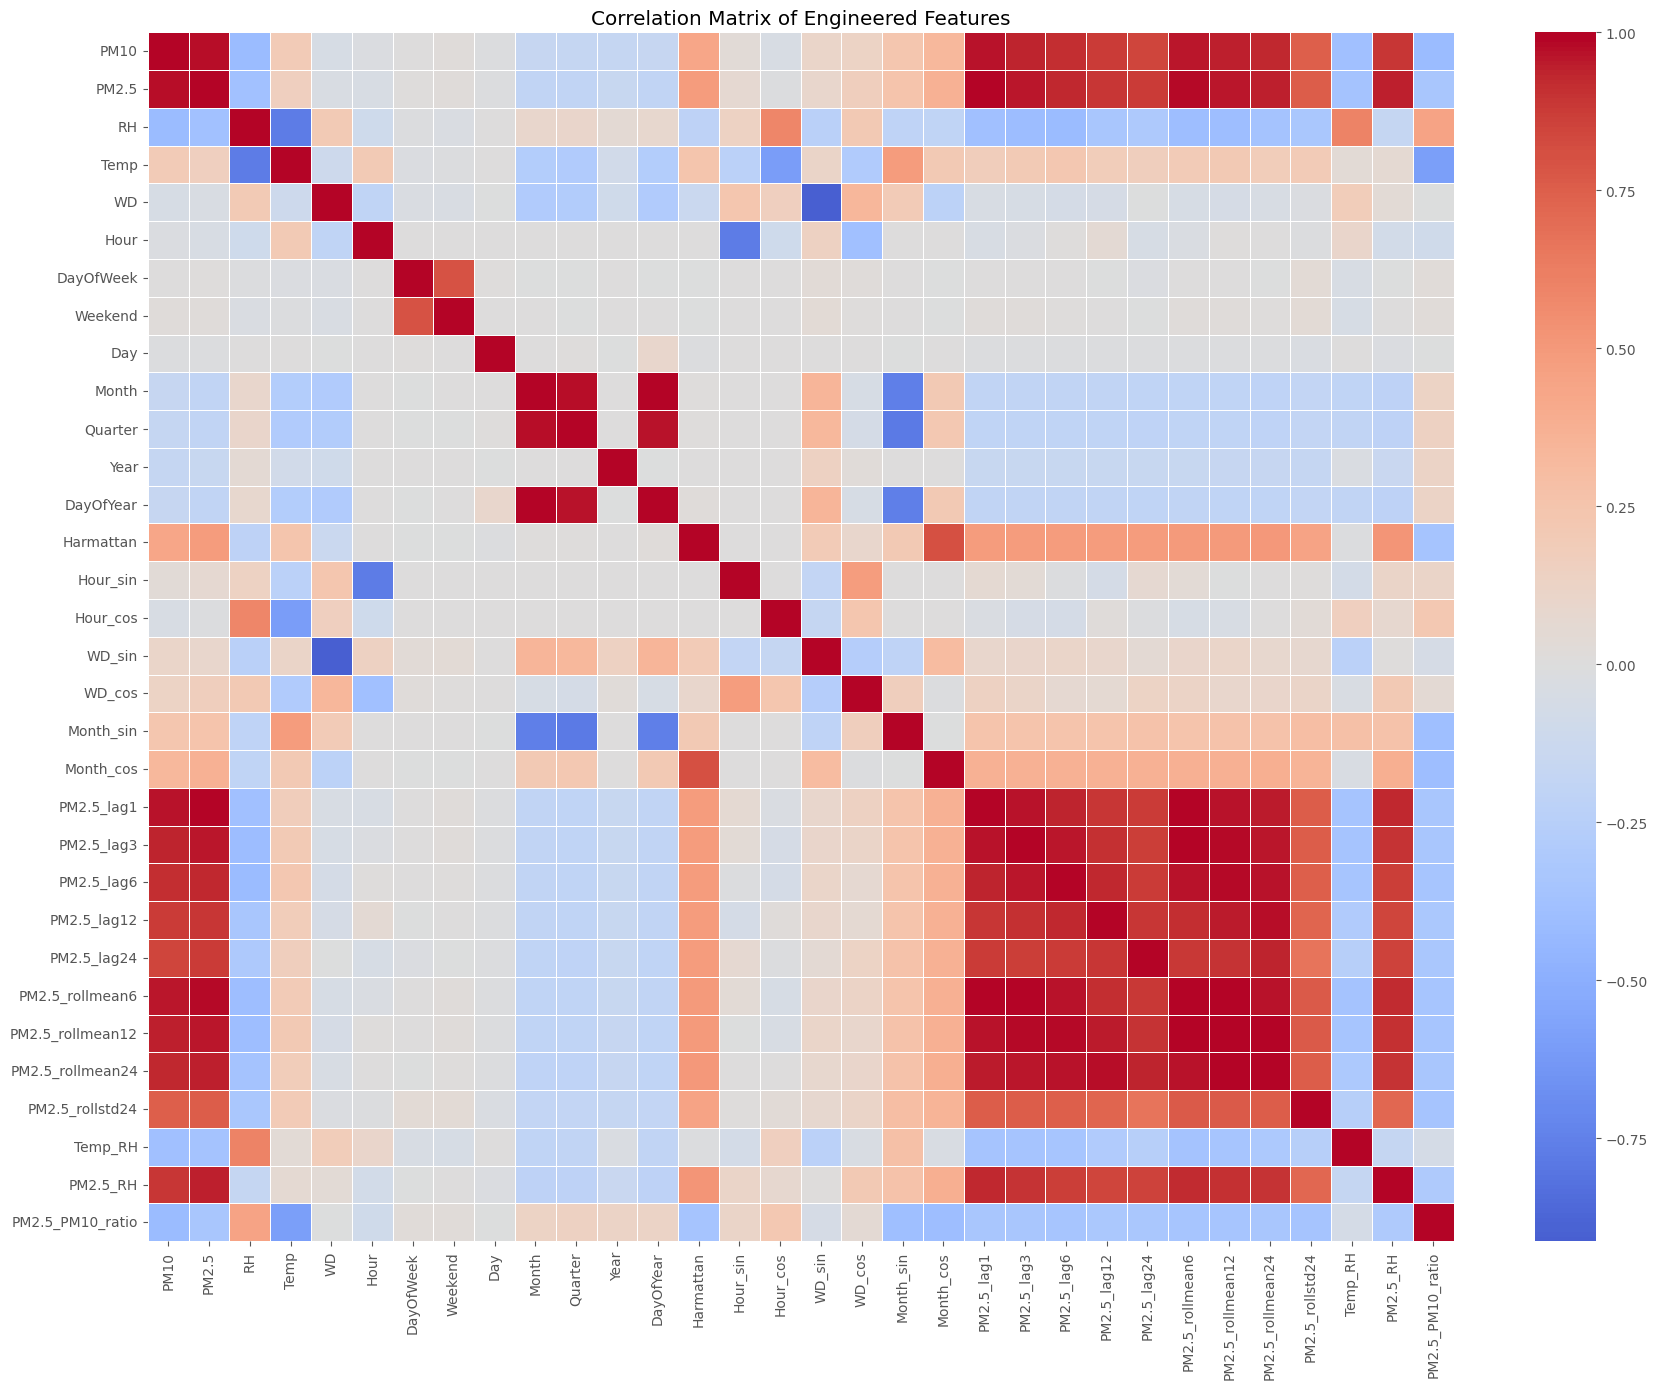

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = (
    air_model_final
    .select_dtypes(include=np.number)
    .corr()
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Engineered Features")

plt.tight_layout()

plt.show()

# Multicollinearity Assessment (Variance Inflation Factor

In [58]:
# Create the Target variable
air_model_final["Target_PM2.5"] = (
    air_model_final["PM2.5"].shift(-1)
)

In [59]:
air_model_final = air_model_final.dropna(subset=["Target_PM2.5"]).copy()

In [60]:
air_model_final[
    ["PM2.5", "Target_PM2.5"]
].head(10)

,PM2.5,Target_PM2.5
24,46.475690,49.260070
25,49.260070,65.935270
26,65.935270,74.101551
27,74.101551,68.002704
28,68.002704,57.365491
29,57.365491,55.529752
30,55.529752,64.628326
31,64.628326,65.230718
32,65.230718,59.365944
33,59.365944,56.372503


In [61]:
air_model_final

,date,PM10,PM2.5,RH,Temp,WD,Hour,DayOfWeek,Weekend,Day,Month,Quarter,Year,DayOfYear,Season,Harmattan,Hour_sin,Hour_cos,WD_sin,WD_cos,Month_sin,Month_cos,PM2.5_lag1,PM2.5_lag3,PM2.5_lag6,PM2.5_lag12,PM2.5_lag24,PM2.5_rollmean6,PM2.5_rollmean12,PM2.5_rollmean24,PM2.5_rollstd24,Temp_RH,PM2.5_RH,PM2.5_PM10_ratio,Target_PM2.5
24,2024-01-02 00:00:00,162.973502,46.475690,93.742130,28.717288,246.205085,0,1,0,2,1,1,2024,2,Dry_Season,1,0.000000,1.000000e+00,-0.914995,-0.403464,5.000000e-01,0.866025,47.898415,46.865442,46.952448,64.659620,65.119368,48.250298,50.100358,71.723232,29.702806,2692.019771,4356.730214,0.285173,49.260070
25,2024-01-02 01:00:00,168.452719,49.260070,95.791463,28.765500,257.415000,1,1,0,2,1,1,2024,2,Dry_Season,1,0.258819,9.659258e-01,-0.975974,-0.217888,5.000000e-01,0.866025,46.475690,48.800760,49.537279,56.190772,108.224682,48.204096,49.522799,69.266373,28.982209,2755.489340,4718.694156,0.292427,65.935270
26,2024-01-02 02:00:00,221.879274,65.935270,94.519977,28.465000,285.770000,2,1,0,2,1,1,2024,2,Dry_Season,1,0.500000,8.660254e-01,-0.962360,0.271776,5.000000e-01,0.866025,49.260070,47.898415,49.924200,54.798287,140.734862,50.872608,50.450881,66.149723,24.662506,2690.511141,6232.200157,0.297167,74.101551
27,2024-01-02 03:00:00,245.929266,74.101551,90.512215,27.994000,294.951667,3,1,0,2,1,1,2024,2,Dry_Season,1,0.707107,7.071068e-01,-0.906664,0.421854,5.000000e-01,0.866025,65.935270,46.475690,46.865442,53.681168,138.152391,55.411959,52.152580,63.480938,19.446036,2533.798955,6707.095576,0.301312,68.002704
28,2024-01-02 04:00:00,217.713974,68.002704,92.148372,27.719000,292.106667,4,1,0,2,1,1,2024,2,Dry_Season,1,0.866025,5.000000e-01,-0.926485,0.376332,5.000000e-01,0.866025,74.101551,49.260070,48.800760,51.907127,126.808911,58.612283,53.493878,61.030680,14.085662,2554.260737,6266.338463,0.312349,57.365491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17538,2025-12-31 18:00:00,89.733081,30.929285,88.645000,29.111833,144.336811,18,2,0,31,12,4,2025,365,Dry_Season,1,-1.000000,-1.836970e-16,0.583019,-0.812458,-2.449294e-16,1.000000,17.110713,14.371522,17.548522,31.295465,17.158656,18.607588,20.112424,22.214230,7.387776,2580.618466,2741.726454,0.344681,64.617278
17539,2025-12-31 19:00:00,183.883245,64.617278,85.148333,28.364167,62.926255,19,2,0,31,12,4,2025,365,Dry_Season,1,-0.965926,2.588190e-01,0.890421,0.455137,-2.449294e-16,1.000000,30.929285,16.059121,17.173440,29.848012,15.002372,26.514894,23.009863,24.281518,11.226447,2415.161518,5502.053555,0.351404,68.951624
17540,2025-12-31 20:00:00,204.157628,68.951624,84.783333,27.799333,41.555254,20,2,0,31,12,4,2025,365,Dry_Season,1,-0.866025,5.000000e-01,0.663342,0.748316,-2.449294e-16,1.000000,64.617278,17.110713,16.001448,27.285175,15.393733,35.339924,26.482067,26.513097,14.288440,2356.920144,5845.948493,0.337737,72.403154
17541,2025-12-31 21:00:00,218.353663,72.403154,89.611667,27.263000,72.567298,21,2,0,31,12,4,2025,365,Dry_Season,1,-0.707107,7.071068e-01,0.954069,0.299585,-2.449294e-16,1.000000,68.951624,30.929285,14.371522,22.458910,13.915408,45.011862,30.644088,28.950086,16.811397,2443.082868,6488.167332,0.331587,64.702803


In [62]:
# Ingore variables that are not predictors in the modelling
X = air_model_final.drop(
    columns=["date", "Target_PM2.5", "Season"],
    errors="ignore"
)

In [63]:
air_model_final

,date,PM10,PM2.5,RH,Temp,WD,Hour,DayOfWeek,Weekend,Day,Month,Quarter,Year,DayOfYear,Season,Harmattan,Hour_sin,Hour_cos,WD_sin,WD_cos,Month_sin,Month_cos,PM2.5_lag1,PM2.5_lag3,PM2.5_lag6,PM2.5_lag12,PM2.5_lag24,PM2.5_rollmean6,PM2.5_rollmean12,PM2.5_rollmean24,PM2.5_rollstd24,Temp_RH,PM2.5_RH,PM2.5_PM10_ratio,Target_PM2.5
24,2024-01-02 00:00:00,162.973502,46.475690,93.742130,28.717288,246.205085,0,1,0,2,1,1,2024,2,Dry_Season,1,0.000000,1.000000e+00,-0.914995,-0.403464,5.000000e-01,0.866025,47.898415,46.865442,46.952448,64.659620,65.119368,48.250298,50.100358,71.723232,29.702806,2692.019771,4356.730214,0.285173,49.260070
25,2024-01-02 01:00:00,168.452719,49.260070,95.791463,28.765500,257.415000,1,1,0,2,1,1,2024,2,Dry_Season,1,0.258819,9.659258e-01,-0.975974,-0.217888,5.000000e-01,0.866025,46.475690,48.800760,49.537279,56.190772,108.224682,48.204096,49.522799,69.266373,28.982209,2755.489340,4718.694156,0.292427,65.935270
26,2024-01-02 02:00:00,221.879274,65.935270,94.519977,28.465000,285.770000,2,1,0,2,1,1,2024,2,Dry_Season,1,0.500000,8.660254e-01,-0.962360,0.271776,5.000000e-01,0.866025,49.260070,47.898415,49.924200,54.798287,140.734862,50.872608,50.450881,66.149723,24.662506,2690.511141,6232.200157,0.297167,74.101551
27,2024-01-02 03:00:00,245.929266,74.101551,90.512215,27.994000,294.951667,3,1,0,2,1,1,2024,2,Dry_Season,1,0.707107,7.071068e-01,-0.906664,0.421854,5.000000e-01,0.866025,65.935270,46.475690,46.865442,53.681168,138.152391,55.411959,52.152580,63.480938,19.446036,2533.798955,6707.095576,0.301312,68.002704
28,2024-01-02 04:00:00,217.713974,68.002704,92.148372,27.719000,292.106667,4,1,0,2,1,1,2024,2,Dry_Season,1,0.866025,5.000000e-01,-0.926485,0.376332,5.000000e-01,0.866025,74.101551,49.260070,48.800760,51.907127,126.808911,58.612283,53.493878,61.030680,14.085662,2554.260737,6266.338463,0.312349,57.365491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17538,2025-12-31 18:00:00,89.733081,30.929285,88.645000,29.111833,144.336811,18,2,0,31,12,4,2025,365,Dry_Season,1,-1.000000,-1.836970e-16,0.583019,-0.812458,-2.449294e-16,1.000000,17.110713,14.371522,17.548522,31.295465,17.158656,18.607588,20.112424,22.214230,7.387776,2580.618466,2741.726454,0.344681,64.617278
17539,2025-12-31 19:00:00,183.883245,64.617278,85.148333,28.364167,62.926255,19,2,0,31,12,4,2025,365,Dry_Season,1,-0.965926,2.588190e-01,0.890421,0.455137,-2.449294e-16,1.000000,30.929285,16.059121,17.173440,29.848012,15.002372,26.514894,23.009863,24.281518,11.226447,2415.161518,5502.053555,0.351404,68.951624
17540,2025-12-31 20:00:00,204.157628,68.951624,84.783333,27.799333,41.555254,20,2,0,31,12,4,2025,365,Dry_Season,1,-0.866025,5.000000e-01,0.663342,0.748316,-2.449294e-16,1.000000,64.617278,17.110713,16.001448,27.285175,15.393733,35.339924,26.482067,26.513097,14.288440,2356.920144,5845.948493,0.337737,72.403154
17541,2025-12-31 21:00:00,218.353663,72.403154,89.611667,27.263000,72.567298,21,2,0,31,12,4,2025,365,Dry_Season,1,-0.707107,7.071068e-01,0.954069,0.299585,-2.449294e-16,1.000000,68.951624,30.929285,14.371522,22.458910,13.915408,45.011862,30.644088,28.950086,16.811397,2443.082868,6488.167332,0.331587,64.702803


In [64]:
# Prepare the Predictors
X_num = X.select_dtypes(include="number")


from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif = pd.DataFrame()

vif["Feature"] = X_num.columns

vif["VIF"] = [
    variance_inflation_factor(X_num.values, i)
    for i in range(X_num.shape[1])
]

vif = vif.sort_values(
    by="VIF",
    ascending=False
)

vif

,Feature,VIF
9,Month,196537.371154
12,DayOfYear,174209.795321
11,Year,22455.622094
2,RH,16122.038992
3,Temp,13168.734002
29,Temp_RH,11862.617749
8,Day,1267.622134
25,PM2.5_rollmean6,1021.140812
26,PM2.5_rollmean12,543.320846
27,PM2.5_rollmean24,261.084180


In [65]:
drop_features = [
    "Year",
    "Quarter",
    "Month",
    "DayOfYear"
]

# Random Forest Feature Importance

In [66]:
# Predictor variables
X = air_model_final.drop(
    columns=[
        "Target_PM2.5",
        "date",
        "Season",
        "Year",
        "Quarter",
        "Month",
        "DayOfYear"
    ],
    errors="ignore"
)

# Target variable
y = air_model_final["Target_PM2.5"]

In [67]:
# Train a RF regressor
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X, y)

RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)

In [68]:
# Extract Feature Importance
importance = (
    pd.Series(
        rf.feature_importances_,
        index=X.columns
    )
    .sort_values(ascending=False)
)

importance

,0
PM2.5,0.971286
PM10,0.003600
PM2.5_lag1,0.002214
PM2.5_rollmean24,0.001670
WD_sin,0.001556
PM2.5_lag12,0.001372
PM2.5_lag6,0.001216
PM2.5_lag3,0.001196
PM2.5_lag24,0.001180
Temp,0.001147


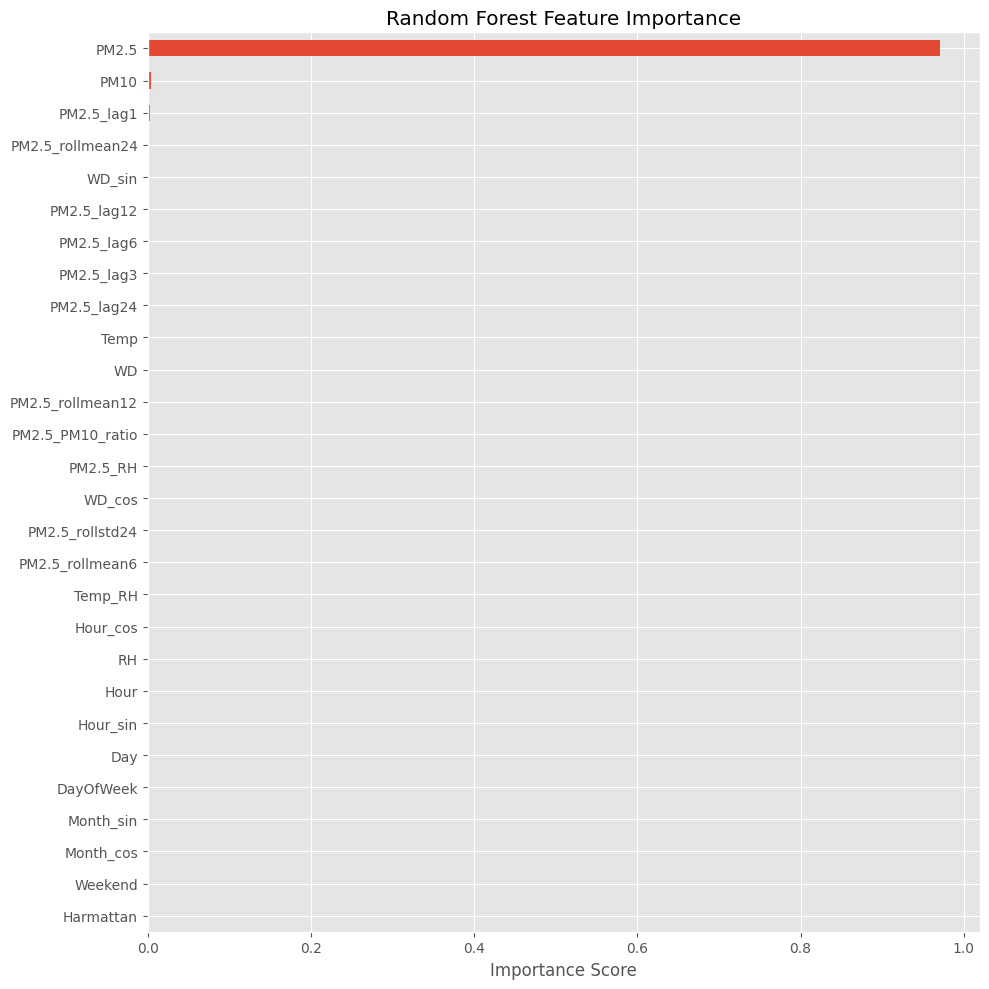

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

importance.sort_values().plot(
    kind="barh"
)

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance Score")

plt.tight_layout()

plt.show()

In [70]:
importance.to_csv(
    "RandomForest_Feature_Importance.csv"
)

In [75]:
# Scientific Feature Evaluation
# Remove current PM2.5 to evaluate the remaining engineered predictors

X_scientific = air_model_final.drop(
    columns=[
        "Target_PM2.5",
        "PM2.5",          # Excluded for scientific evaluation
        "date",
        "Season",         # Will be encoded later
        "Year",
        "Quarter",
        "Month",
        "DayOfYear"
    ],
    errors="ignore"
)

y = air_model_final["Target_PM2.5"]

In [76]:
print(X_scientific.shape)

X_scientific.head()

(17519, 27)


,PM10,RH,Temp,WD,Hour,DayOfWeek,Weekend,Day,Harmattan,Hour_sin,Hour_cos,WD_sin,WD_cos,Month_sin,Month_cos,PM2.5_lag1,PM2.5_lag3,PM2.5_lag6,PM2.5_lag12,PM2.5_lag24,PM2.5_rollmean6,PM2.5_rollmean12,PM2.5_rollmean24,PM2.5_rollstd24,Temp_RH,PM2.5_RH,PM2.5_PM10_ratio
24,162.973502,93.742130,28.717288,246.205085,0,1,0,2,1,0.000000,1.000000,-0.914995,-0.403464,0.5,0.866025,47.898415,46.865442,46.952448,64.659620,65.119368,48.250298,50.100358,71.723232,29.702806,2692.019771,4356.730214,0.285173
25,168.452719,95.791463,28.765500,257.415000,1,1,0,2,1,0.258819,0.965926,-0.975974,-0.217888,0.5,0.866025,46.475690,48.800760,49.537279,56.190772,108.224682,48.204096,49.522799,69.266373,28.982209,2755.489340,4718.694156,0.292427
26,221.879274,94.519977,28.465000,285.770000,2,1,0,2,1,0.500000,0.866025,-0.962360,0.271776,0.5,0.866025,49.260070,47.898415,49.924200,54.798287,140.734862,50.872608,50.450881,66.149723,24.662506,2690.511141,6232.200157,0.297167
27,245.929266,90.512215,27.994000,294.951667,3,1,0,2,1,0.707107,0.707107,-0.906664,0.421854,0.5,0.866025,65.935270,46.475690,46.865442,53.681168,138.152391,55.411959,52.152580,63.480938,19.446036,2533.798955,6707.095576,0.301312
28,217.713974,92.148372,27.719000,292.106667,4,1,0,2,1,0.866025,0.500000,-0.926485,0.376332,0.5,0.866025,74.101551,49.260070,48.800760,51.907127,126.808911,58.612283,53.493878,61.030680,14.085662,2554.260737,6266.338463,0.312349


In [77]:
# Train a RF regressor
from sklearn.ensemble import RandomForestRegressor

rf_scientific = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_scientific.fit(X_scientific, y)

RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)

In [78]:
# Extract Feature Importance
importance_scientific = (
    pd.Series(
        rf_scientific.feature_importances_,
        index=X_scientific.columns
    )
    .sort_values(ascending=False)
)

importance_scientific

,0
PM10,0.612029
PM2.5_RH,0.183631
PM2.5_lag1,0.130768
PM2.5_rollmean6,0.038740
RH,0.006072
PM2.5_PM10_ratio,0.003555
PM2.5_rollmean24,0.002740
Temp_RH,0.002193
WD,0.001616
PM2.5_rollmean12,0.001559


In [79]:
importance_df = (
    importance_scientific
    .reset_index()
)

importance_df.columns = [
    "Feature",
    "Importance"
]

importance_df

,Feature,Importance
0,PM10,0.612029
1,PM2.5_RH,0.183631
2,PM2.5_lag1,0.130768
3,PM2.5_rollmean6,0.038740
4,RH,0.006072
5,PM2.5_PM10_ratio,0.003555
6,PM2.5_rollmean24,0.002740
7,Temp_RH,0.002193
8,WD,0.001616
9,PM2.5_rollmean12,0.001559


In [80]:
#Percentage Contribution
importance_df["Importance (%)"] = (
    importance_df["Importance"] * 100
)

importance_df

,Feature,Importance,Importance (%)
0,PM10,0.612029,61.202938
1,PM2.5_RH,0.183631,18.363144
2,PM2.5_lag1,0.130768,13.076833
3,PM2.5_rollmean6,0.038740,3.874029
4,RH,0.006072,0.607176
5,PM2.5_PM10_ratio,0.003555,0.355507
6,PM2.5_rollmean24,0.002740,0.273957
7,Temp_RH,0.002193,0.219346
8,WD,0.001616,0.161617
9,PM2.5_rollmean12,0.001559,0.155907


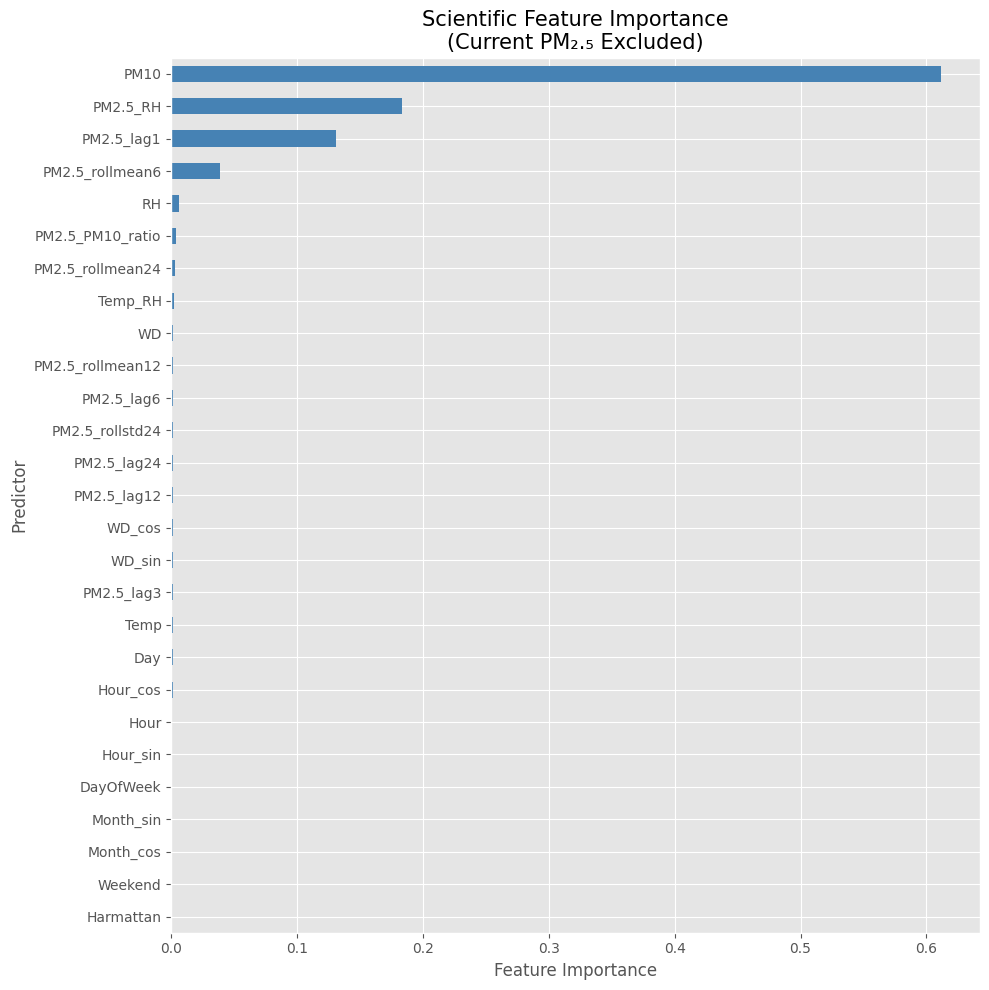

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

importance_scientific.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Scientific Feature Importance\n(Current PM₂.₅ Excluded)",
    fontsize=15
)

plt.xlabel("Feature Importance")

plt.ylabel("Predictor")

plt.tight_layout()

plt.show()

In [82]:
importance_df.to_csv(
    "Scientific_Feature_Importance.csv",
    index=False
)

importance_df.head(10)

,Feature,Importance,Importance (%)
0,PM10,0.612029,61.202938
1,PM2.5_RH,0.183631,18.363144
2,PM2.5_lag1,0.130768,13.076833
3,PM2.5_rollmean6,0.038740,3.874029
4,RH,0.006072,0.607176
5,PM2.5_PM10_ratio,0.003555,0.355507
6,PM2.5_rollmean24,0.002740,0.273957
7,Temp_RH,0.002193,0.219346
8,WD,0.001616,0.161617
9,PM2.5_rollmean12,0.001559,0.155907


In [84]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor
import pandas as pd


X_rfe = X_scientific.copy()

y = air_model_final["Target_PM2.5"]

#Create the Estimator
rf_estimator = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

#Train the model
rfe = RFE(
    estimator=rf_estimator,
    n_features_to_select=15,
    step=1
)

rfe.fit(X_rfe, y)

RFE(estimator=RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                    random_state=42),
    n_features_to_select=15)

In [85]:
# Create the Result Table
rfe_results = pd.DataFrame({
    "Feature": X_rfe.columns,
    "Selected": rfe.support_,
    "Ranking": rfe.ranking_
})

rfe_results = rfe_results.sort_values(
    by=["Selected", "Ranking"],
    ascending=[False, True]
)

rfe_results

,Feature,Selected,Ranking
0,PM10,True,1
1,RH,True,1
3,WD,True,1
12,WD_cos,True,1
15,PM2.5_lag1,True,1
17,PM2.5_lag6,True,1
18,PM2.5_lag12,True,1
19,PM2.5_lag24,True,1
20,PM2.5_rollmean6,True,1
21,PM2.5_rollmean12,True,1


In [86]:
# List the Final Feature
selected_features = (
    rfe_results[rfe_results["Selected"]]
    ["Feature"]
    .tolist()
)

print(selected_features)

# Save the result
rfe_results.to_csv(
    "RFE_Feature_Selection.csv",
    index=False
)

['PM10', 'RH', 'WD', 'WD_cos', 'PM2.5_lag1', 'PM2.5_lag6', 'PM2.5_lag12', 'PM2.5_lag24', 'PM2.5_rollmean6', 'PM2.5_rollmean12', 'PM2.5_rollmean24', 'PM2.5_rollstd24', 'Temp_RH', 'PM2.5_RH', 'PM2.5_PM10_ratio']


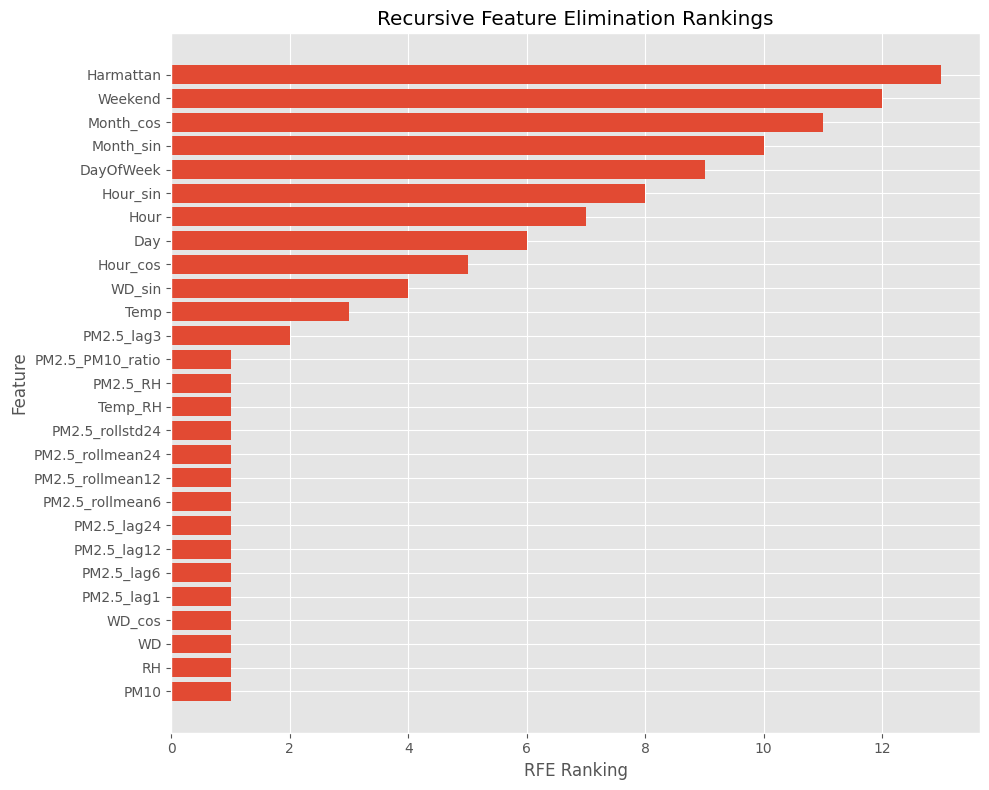

In [87]:
import matplotlib.pyplot as plt

plot_df = (
    rfe_results
    .sort_values("Ranking")
)

plt.figure(figsize=(10,8))

plt.barh(
    plot_df["Feature"],
    plot_df["Ranking"]
)

plt.xlabel("RFE Ranking")
plt.ylabel("Feature")
plt.title("Recursive Feature Elimination Rankings")

plt.tight_layout()

plt.show()

In [88]:
# ==============================
# FULL FEATURE DATASET
# ==============================

X_full = air_model_final.drop(
    columns=[
        "Target_PM2.5",
        "date",
        "Season",      # Will be encoded later if required
        "Year",
        "Quarter",
        "Month",
        "DayOfYear"
    ],
    errors="ignore"
)

y = air_model_final["Target_PM2.5"]

print("X_full shape:", X_full.shape)
print("Target shape:", y.shape)

X_full shape: (17519, 28)
Target shape: (17519,)


In [89]:
# Selected features from RFE
selected_features = (
    rfe_results
    .loc[rfe_results["Selected"], "Feature"]
    .tolist()
)

selected_features

['PM10',
 'RH',
 'WD',
 'WD_cos',
 'PM2.5_lag1',
 'PM2.5_lag6',
 'PM2.5_lag12',
 'PM2.5_lag24',
 'PM2.5_rollmean6',
 'PM2.5_rollmean12',
 'PM2.5_rollmean24',
 'PM2.5_rollstd24',
 'Temp_RH',
 'PM2.5_RH',
 'PM2.5_PM10_ratio']

In [90]:
# ==============================
# RFE FEATURE DATASET
# ==============================

X_rfe = air_model_final[selected_features]

print("X_rfe shape:", X_rfe.shape)

X_rfe shape: (17519, 15)


In [91]:
print("Full Features :", X_full.shape[1])
print("RFE Features  :", X_rfe.shape[1])

Full Features : 28
RFE Features  : 15


In [92]:
# Save predictor datasets

X_full.to_csv("X_full_features.csv", index=False)

X_rfe.to_csv("X_rfe_features.csv", index=False)

y.to_csv("Target_PM2.5.csv", index=False)

In [93]:
# Full modelling dataset
full_dataset = X_full.copy()
full_dataset["Target_PM2.5"] = y

full_dataset.to_csv(
    "AirQuality_Full_Model_Dataset.csv",
    index=False
)

# Optimized modelling dataset
rfe_dataset = X_rfe.copy()
rfe_dataset["Target_PM2.5"] = y

rfe_dataset.to_csv(
    "AirQuality_RFE_Model_Dataset.csv",
    index=False
)

In [94]:
print(full_dataset.shape)

print(rfe_dataset.shape)

(17519, 29)
(17519, 16)
